<a href="https://colab.research.google.com/github/Pvichente/st1/blob/main/S2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conexión: S2 & **Profundiza**


## Instalación de dependencias:

In [ ]:
!pip install -U pysentimiento #dependencia del modelo

In [ ]:
!pip install accelerate -U  #dependencias para uso de GPUs

In [ ]:
!pip install transformers[torch] #dependencia de matrices, torch

# Primera sesión:
- **Corpus**: un cuerpo de texto, en singular. "Corpora" es la forma plural. Un corpus es un conjunto grande y estructurado de textos utilizados para realizar análisis lingüísticos y entrenar modelos de procesamiento del lenguaje natural (NLP).

- **Léxico**: en esencia, un diccionario que incluye palabras y sus significados.Un léxico se refiere al inventario de palabras o términos que aparecen en un corpus o conjunto de datos textuales, a menudo con información adicional como su significado, frecuencia o relaciones con otras palabras.

- **Token**: una pieza o "entidad" individual que resulta de descomponer el texto en función de reglas específicas.  Usualmente una palabra, pero también puede ser una sub-palabra, un carácter o una secuencia de caracteres, que es el resultado de un proceso de tokenización.

## Temas de la Sesión 02:


*   Tema: lemmatización, detección de idioma y generación de datos con ChatGPT
    *   Laboratorio: Análisis de sentimientos, con NLTK.
*   Uso de modelos pre entrenados: Hugging Face
    *   Laboratorio: Análisis de sentimientos, con modelos pre entrenados.
*   Tema: word2vec & T-SNE



## S1: procesamiento básico

In [ ]:
!pip install -q gensim nltk scikit-learn matplotlib seaborn emoji langdetect

import pandas as pd, numpy as np, regex as re
import nltk, matplotlib.pyplot as plt, seaborn as sns
from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.manifold import TSNE
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import pandas as pd
import regex as re
import nltk
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
import string
import spacy
from langdetect import detect
nlp = spacy.load("en_core_web_sm")

In [ ]:
from wordcloud import WordCloud

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

In [ ]:
def nube_palabras(corpus, stopwords, color):
    stopwords = set(stopwords)
    wordcloud = WordCloud(
        background_color=color,
        stopwords=stopwords,
        max_words=100,
        max_font_size=50,
        random_state=1,
        collocations=False)

    wordcloud=wordcloud.generate(str(corpus))

    fig = plt.figure(1, figsize=(15, 15))
    plt.imshow(wordcloud)
    plt.axis('on')
    plt.show()


In [ ]:
texto = "Disneyland Paris 😊 (@DisneylandParis) <p> <br> is the first brand in France to use the new 360 video format, allowing 360-degree videos to be uploaded and viewed directly on its timeline."

In [ ]:
import emoji
def elimina_emojis(texto):
    return emoji.replace_emoji(texto, replace='')

In [ ]:
texto = elimina_emojis( texto )

In [ ]:
print(texto)

In [ ]:
def elimina_html(texto):
    patron = re.compile(r'<.*?>')
    return re.sub(patron, '', texto)

In [ ]:
texto = elimina_html(texto)

In [ ]:
print(texto)

In [ ]:
def quita_puntuacion(texto):
    traductor = str.maketrans(str.maketrans('','', string.punctuation))
    return texto.translate(traductor)

In [ ]:
string.punctuation

In [ ]:
texto = quita_puntuacion( texto )

In [ ]:
print(texto)

In [ ]:
def elimina_numeros(cadena):
    # Reemplaza todos los dígitos (\d) en la cadena por una cadena vacía
    return re.sub(r'\d+', '', cadena)

In [ ]:
texto = elimina_numeros( texto )

In [ ]:
texto

In [ ]:
def tokeniza(texto):
    return re.findall(r"\b\p{L}+\b", texto)

In [ ]:
vtexto = tokeniza(texto.lower())

In [ ]:
def quita_sw(vpalabras, idioma= "english"):
    return [ palabra for palabra in vpalabras if palabra not in stopwords.words(idioma) ]

In [ ]:
vtexto = quita_sw(vtexto)

In [ ]:
print(vtexto)

In [ ]:

def lematiza(vtexto):
    documento = nlp(" ".join(vtexto))
    return [ token.lemma_ for token in documento]

In [ ]:
vtexto = lematiza(vtexto)

In [ ]:
print(vtexto)

In [ ]:
def preprocesa(texto, idioma="english"):
        texto = re.sub(r"[^\p{Latin}\s]", "", str(texto))
        # 1. Eliminar emojis
        texto = emoji.replace_emoji(str(texto), replace="")
        # 2. Eliminar HTML
        texto = re.sub(r"<.*?>", "", texto)
        # 3. Eliminar puntuación
        texto = texto.translate(str.maketrans("", "", string.punctuation))
        # 4. Eliminar números
        texto = re.sub(r"\d+", "", texto)
        # 5. Convertir a minúsculas
        texto = texto.lower()
        # 6. Tokenizar solo letras con Unicode
        tokens = re.findall(r"\b\p{L}+\b", texto)
        # 7. Quitar stopwords
        tokens = [
            palabra for palabra in tokens
            if palabra not in stopwords.words(idioma)
        ]
        # 8. Lematizar
        doc = nlp(" ".join(tokens))
        lemmas = [token.lemma_ for token in doc]
        return lemmas

In [ ]:
def lista_a_cadena(lista):
    return " ".join(lista)

In [ ]:
texto = "Disneyland Paris 😊 (@DisneylandParis) <p> <br> is the first brand in France to use the new 360 video format, allowing 360-degree videos to be uploaded and viewed directly on its timeline."

In [ ]:
print(preprocesa(texto))

| Tipo de modelo o tarea | Remover Stopwords | Aplicar Stemming / Lemmatization | Justificación / Comentario |
|-------------------------|------------------|----------------------------------|-----------------------------|
| Bag of Words (BoW) | Sí | Sí | Elimina ruido y reduce dimensionalidad. |
| TF-IDF (Term Frequency–Inverse Document Frequency) | Sí | Sí | Destaca palabras relevantes y evita duplicados de raíz. |
| Clasificación de textos (Naive Bayes, SVM, Regresión Logística) | Sí | Sí | Mejora precisión reduciendo variantes morfológicas. |
| Análisis de sentimientos clásico | Sí | Opcional | Algunas stopwords (como “not”) aportan contexto y deben conservarse. |
| Modelado de temas (LDA, NMF) | Sí | Lemmatization | Favorece la coherencia de temas al agrupar variantes. |
| Embeddings clásicos (Word2Vec, GloVe, FastText) | A veces | A veces | En corpus grandes puede omitirse; los embeddings ya capturan contexto. |
| NER (Reconocimiento de Entidades Nombradas) | No | No | Requiere mantener contexto completo y capitalización. |
| POS tagging (Etiquetado gramatical) | No | No | Necesita forma y función gramatical de cada palabra. |
| Parsing (análisis sintáctico o de dependencias) | No | No | Depende de la estructura sintáctica completa. |
| Modelos basados en Transformers (BERT, RoBERTa, GPT, T5) | No | No | Los modelos ya manejan contexto y morfología. |
| Resumen de textos (extractivo o generativo) | Depende | No | En resúmenes extractivos puede aplicarse mínimamente. |
| Chatbots y generación de texto | No | No | Requiere conservar contexto completo del lenguaje natural. |

## ChatGPT reviews [DAILY UPDATED]: Google Play Store reviews of ChatGPT App


**This dataset mainly consists of daily-updated user reviews and ratings for the ChatGPT Android App. It also contains data on the relevancy of these reviews and the dates they were posted.**

[ChatGTP reviews app](https://www.kaggle.com/datasets/ashishkumarak/chatgpt-reviews-daily-updated/data)

In [ ]:
corpus = pd.read_csv("https://drive.google.com/uc?id=1kbk9FlYax4F9UlHf60AtpCCcf_-VaxCF")

In [ ]:
corpus.shape

In [ ]:
corpus.head()

In [ ]:
corpus_1000 = corpus.sample(1000)

In [ ]:
corpus_1000.head()

In [ ]:
corpus_1000 = corpus_1000[["content", "score"]]

In [ ]:
corpus_1000.head()

In [ ]:
corpus_1000["vectors"] = corpus_1000.content.apply(preprocesa)

In [ ]:
corpus_1000.head()

In [ ]:
corpus_1000["vec2string"] = corpus_1000.vectors.apply(lista_a_cadena)

In [ ]:
corpus_1000.head()

In [ ]:
cadena = " ".join(cadena for cadena in corpus_1000.vec2string )

In [ ]:
nube_palabras(cadena,["br", "one"], "white")

# Ingeniería de características:

## Bag of Words:

Bag of Words (BoW) es una técnica simple y fundamental en Procesamiento de Lenguaje Natural (NLP) que representa un documento como una bolsa (conjunto desordenado) de palabras, ignorando el orden, pero manteniendo la frecuencia de cada palabra.
En BoW **no importa el orden, la gramática ni la estructura**. Solo cuenta cuántas veces aparece cada palabra en un documento.

In [ ]:
corpus_1000.head()

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# 1. Diez tweets ficticios de Donald Trump
documentos_ = corpus_1000.vec2string.to_list()
print(documentos_)



In [ ]:
# 2. Vectorización con Bag of Words
vectorizador = CountVectorizer(stop_words = "english", ngram_range=(1,2), min_df=2, max_df=6)

In [ ]:
X = vectorizador.fit_transform(documentos_)

In [ ]:
# 3. Convertir a DataFrame para visualizar la matriz
df = pd.DataFrame(X.toarray(), columns = vectorizador.get_feature_names_out() )
pd.set_option("display.max_columns", None)



In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
# 4. Mostrar la matriz de características

In [ ]:
frecuencias = df.sum()
frecuencias

In [ ]:
frecuencias.head(10).plot(kind="bar")

## Tarea 01: Clasificación de documentos con TF-IDF y Árbol de Decisión

### Objetivo
Aplicar técnicas de representación vectorial y aprendizaje supervisado para clasificar documentos de texto según su contenido temático.  
Este flujo básico de analítica de textos,  incluye preprocesamiento, vectorización mediante TF-IDF y clasificación usando un modelo de Árbol de Decisión (*Decision Tree Classifier*).

---

### Descripción general
En esta tarea, el conjunto de documentos será transformado desde su forma textual hacia una representación numérica basada en **TF-IDF (Term Frequency–Inverse Document Frequency)**.  
Luego, se entrenará un **modelo de Árbol de Decisión** que aprenderá a distinguir entre distintas categorías de texto, para el ejemplo.

El flujo de trabajo se compone de los siguientes pasos:

1. **Carga del conjunto de datos**  


2. **Preprocesamiento**  

3. **Representación mediante TF-IDF**  

4. **Entrenamiento del modelo**  
   Entrenar un **Árbol de Decisión (`DecisionTreeClassifier`)** para aprender patrones que permitan clasificar los documentos.

5. **Evaluación**  

6. **Predicción de nuevos textos**  
   Probar el modelo con textos nuevos escritos por el estudiante y observar las categorías asignadas.

---


In [ ]:
corpus_1000.head()

In [ ]:
# Importar el TfidfVectorizer de scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Dividir los datos en características (X) y etiquetas (y)

X = corpus_1000["vec2string"]
y = corpus_1000["score"]


# Crear el vectorizador TF-IDF
tfidf = TfidfVectorizer()


# Ajustar y transformar los datos de texto en vectores TF-
X_tfidf = tfidf.fit_transform(X)



In [ ]:
# 3. Convertir a DataFrame para visualizar la matriz
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns = tfidf.get_feature_names_out() )
pd.set_option("display.max_columns", None)
df_tfidf.head()

In [ ]:
# Dividir los datos en conjunto de entrenamiento y prueba
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size= 0.2)

# Mostrar las dimensiones del conjunto de entrenamiento
X_train.shape


In [ ]:
# Importar el Árbol de Decisión de scikit-learn
from sklearn.tree import DecisionTreeClassifier

clasificador = DecisionTreeClassifier(max_depth=5)

In [ ]:
#Entranamiento del modelo
clasificador.fit(X_train, y_train)

In [ ]:
from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt

In [ ]:
# Configurar el tamaño de la figura
plt.figure(figsize=(50, 10))
class_names_str = [str(c) for c in clasificador.classes_]
# Graficar el árbol
plot_tree(clasificador, feature_names=tfidf.get_feature_names_out(),
          class_names=class_names_str, filled=True, rounded=True, fontsize=10)
# Mostrar la gráfica
plt.show()

In [ ]:
# Predicción del modelo
y_pred = clasificador.predict(X_test)


In [ ]:
# Importar las métricas de evaluación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calcular la precisión del modelo
precision = accuracy_score(y_test, y_pred)
print(precision * 100)


In [ ]:
# Guardar el modelo
import pickle

with open("dt.pkl", "wb") as objeto:
    pickle.dump(clasificador, objeto)


## VADER (Valence Aware Dictionary and sEntiment Reasoner)
es una herramienta de análisis de sentimientos basada en un léxico y en reglas, diseñada específicamente para captar las expresiones de sentimientos en textos de redes sociales. Se integra en la biblioteca NLTK (Natural Language Toolkit) de Python, facilitando su uso en aplicaciones de procesamiento de lenguaje natural.

* Características Principales de VADER:

1. Adaptación a Redes Sociales: VADER está optimizado para manejar el lenguaje informal, abreviaturas, emoticonos y otros elementos comunes en plataformas como Twitter y Facebook.

2. Análisis de Sentimientos: Proporciona puntuaciones que reflejan la intensidad y polaridad del sentimiento en un texto, clasificándolos como positivos, negativos, neutrales o una combinación de estos.

3. Basado en Léxico y Reglas: Utiliza un diccionario de palabras con puntuaciones de sentimiento predefinidas y aplica reglas para ajustar estas puntuaciones según el contexto, como la presencia de signos de exclamación o mayúsculas.

In [ ]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')

In [ ]:
analizador = SentimentIntensityAnalyzer()

In [ ]:
scores = analizador.polarity_scores("ChatGPT is  very bad!")

In [ ]:
print(scores)

In [ ]:
def nltk_analizador(texto):
    if not isinstance(texto, str):
        texto = str(texto)
    resultado = analizador.polarity_scores(texto)
    if resultado["compound"] >= 0.05:
        return "Positivo"
    elif resultado["compound"] <= -0.05:
        return "Negativo"
    else:
        return "Neutral"

In [ ]:
nltk_analizador("ChatGPT is incredibly useful for generating content ideas!")

# Laboratorio: Análisis de Sentimientos con VADER en Amazon Kozmos
Empresa: **Kozmos**, que opera en Amazon en los sectores de textiles para el hogar y ropa de uso diario.

Enfoque: Mejorar la satisfacción del cliente y maximizar las ventas a través de los comentarios de los clientes.

## **Objetivo:**
En este laboratorio, aprenderás a realizar un **análisis de sentimientos** en reseñas de productos de **Amazon Kozmos** utilizando el método **VADER** incluido en la biblioteca **NLTK**. Al final del laboratorio, serás capaz de cargar datos de reseñas, preprocesarlos y analizar los sentimientos que expresan.

Realiza lo siguiente:
1. Cargar y preprocesar un conjunto de datos de reseñas de Amazon Kozmos.
2. Utilizar VADER para realizar un análisis de sentimientos.
3. Clasificar las reseñas en positivas, negativas o neutrales.
4. Visualizar los resultados del análisis de sentimientos.

https://drive.google.com/file/d/1tRuKICF7DcGNdhDJEm_InxOQw_PjiAFJ/view?usp=sharing

In [ ]:
kozmos = pd.read_csv("https://drive.google.com/uc?id=1tRuKICF7DcGNdhDJEm_InxOQw_PjiAFJ")

In [ ]:
kozmos.head()

In [ ]:
#Aplica VADER a todos los documentos del corpus.
kozmos["sentimiento_vader"] = kozmos.Review.apply(nltk_analizador)

In [ ]:
#agregar columna kozmos
kozmos.head()

In [ ]:
#aplicar la función a todos los documentos de Review
scores_kozmos = kozmos.sentimiento_vader.value_counts()

In [ ]:
scores_kozmos

### Visualiza el resultado de score_kozmos

In [ ]:
def grafica_clasificacion(datos):
    plt.bar(datos.index, datos.values, color=['green', 'gray', 'red'])
    plt.xlabel("Categorías de sentimiento")
    plt.ylabel("Frecuencia")
    plt.title("Distribución de sentimientos (Kozmos)")
    plt.show()

In [ ]:
grafica_clasificacion(scores_kozmos)

## Continua con el laboratorio:
1. Agrea las columnas de vectors y vec2string, con las funciones de:
    * preprocesa(texto, idioma="english") y
    * vectors -> lista_a_cadena(lista)

2. Utiliza tu clasificador entrenado con el Árbol de decisión y asigna el número de estrellas de cada documento.

3. Crea la gráfica para revisar resultados.

In [ ]:
# Utilizar el clasificador.
review_x = ["chatgpt app is not that bad"]
review_x_tfidf = tfidf.transform(review_x)
print(clasificador.predict(review_x_tfidf)[0])


In [ ]:
# Tip: tienes el clasificador como una función.
def dt_clasificador(texto):
    if isinstance(texto, str) and len(texto) > 0:
        review_x = [texto]
        review_x_tfidf = tfidf.transform(review_x)
        return clasificador.predict(review_x_tfidf)[0]
    return -1

In [ ]:
kozmos["vectors"] = kozmos.Review.apply(preprocesa)

In [ ]:
kozmos["vec2string"] = kozmos.vectors.apply(lista_a_cadena)

In [ ]:
kozmos_1000 = kozmos.sample(frac=.20)

In [ ]:
kozmos_1000.head()

In [ ]:
kozmos_1000["dtree"] = kozmos_1000.vec2string.apply(dt_clasificador)

In [ ]:
kozmos_1000.head()

In [ ]:
grafica_clasificacion(kozmos_1000.dtree.value_counts())

## Tarea 02: Reconocimiento de Entidades Nombradas (NER) con spaCy

### Objetivo
Aplicar técnicas de procesamiento de lenguaje natural para **identificar entidades nombradas** en textos utilizando el componente **NER (Named Entity Recognition)** de spaCy.  
El propósito es reconocer y analizar categorías como personas, organizaciones, lugares, fechas y cantidades, además de mostrar cómo extender o ajustar el modelo con ejemplos adicionales.

---

### Descripción general
Esta tarea utiliza la librería **spaCy** para procesar texto y extraer entidades nombradas de forma automática.  
Se trabajará con el modelo preentrenado `en_core_web_sm` (para inglés) o `es_core_news_sm` (para español), y se implementará un flujo de trabajo que incluye carga del modelo, análisis de texto y visualización de entidades

---

### Flujo de trabajo

1. **Instalación y carga del modelo spaCy**  

2. **Aplicación del modelo NER sobre textos**  

3. **Análisis y conteo de entidades**  
   - Contar la frecuencia por tipo de entidad (por ejemplo, número de `PERSON`, `ORG`, `GPE`).  

4. **Personalización y reentrenamiento básico del modelo**  
   - Definir ejemplos adicionales con nuevas entidades en el formato:
     ```python
     ("Texto de ejemplo", {"entities": [(inicio, fin, "ETIQUETA")]})
     ```


In [ ]:
import spacy
from spacy.training import Example

# =============================================
# Definir Datos
# =============================================
# (texto, {"entities": [(inicio, fin, etiqueta)]})
TRAIN_DATA = [
    ("Apple is looking at buying U.K. startup for $1 billion",
     {"entities": [(0, 5, "ORG"), (27, 30, "GPE"), (44, 54, "MONEY")]}),

    ("Elon Musk founded SpaceX in 2002",
     {"entities": [(0, 9, "PERSON"), (18, 24, "ORG"), (28, 32, "DATE")]}),

    ("Google opened a new office in Mexico",
     {"entities": [(0, 6, "ORG"), (31, 37, "GPE")]}),

    ("Amazon acquired Ring in 2018",
     {"entities": [(0, 6, "ORG"), (16, 20, "ORG"), (24, 28, "DATE")]}),
]


In [ ]:
# =============================================
# Crear un modelo.
# =============================================
# Se crea un modelo de inglés vacío
nlp = spacy.blank("en")
ner = nlp.add_pipe("ner")

# Añadimos el componente NER
for dato, anotaciones in TRAIN_DATA:
    for entidad in anotaciones.get("entities"):
        ner.add_label(entidad[2])

# Registramos las etiquetas encontradas


print("\nEtiquetas añadidas:", ner.labels)

In [ ]:
# =============================================
# Entrenamiento
# =============================================
optimizer = nlp.begin_training()

# Entrenamos durante 20 iteraciones (épocas)
for epoch in range(20):
    losses = {}
    for text, annotations in TRAIN_DATA:
        doc = nlp.make_doc(text)
        example = Example.from_dict(doc, annotations)
        nlp.update([example], drop=0.2, sgd=optimizer, losses=losses)
    if epoch % 5 == 0:
        print(f"Época {epoch}: Pérdida NER = {losses.get('ner', 0):.4f}")

print("\nEntrenamiento completado.")


In [ ]:
# =============================================
# Probar el modelo.
# =============================================
texts = [
    "Apple acquired Beats in 2014",
    "Elon Musk visited Mexico last year",
    "Google and Amazon are competing in AI",
]
# Pruebas
for texto in texts:
    docto = nlp(texto)
    print(texto)
    for entidad in docto.ents:
        print(entidad.text, entidad.label_)

## Tarea 03: Clasificación de textos con Word2Vec y visualización con t-SNE

### Objetivo
Implementar un flujo de analítica de textos que combine **representaciones semánticas mediante Word2Vec** con un **modelo supervisado de clasificación**, y explorar el espacio vectorial generado a través de una visualización con **t-SNE (t-Distributed Stochastic Neighbor Embedding)**.

---

### Descripción general
Esta tarea tiene como propósito mostrar cómo los modelos de vectorización de palabras (*word embeddings*) permiten representar el significado semántico de los textos de manera numérica.  
Se entrenará un modelo **Word2Vec** sobre un conjunto de documentos o reseñas, se construirán representaciones promedio de cada texto y se usará un clasificador (por ejemplo, Regresión Logística o SVM) para predecir la categoría del documento.  
Finalmente, se aplicará **t-SNE** para reducir la dimensionalidad y **visualizar gráficamente las relaciones semánticas** entre las palabras o los documentos.

---

### Flujo de trabajo

1. **Carga y preprocesamiento del corpus**

2. **Entrenamiento del modelo Word2Vec**
   - Usar la implementación de `gensim.models.Word2Vec`.  
   - Configurar parámetros como `vector_size`, `window`, `min_count` y `epochs`.  
   - Verificar el vocabulario aprendido y explorar palabras similares mediante `model.wv.most_similar()`.

3. **Representación de documentos**
   - Construir un vector por documento mediante el promedio de los vectores de sus palabras.  
   - Crear una matriz `X` con los embeddings de los documentos y un vector `y` con las etiquetas.

4. **Clasificación supervisada**
   - Dividir los datos en entrenamiento y prueba con `train_test_split`.  
   - Entrenar un modelo de clasificación (por ejemplo, `LogisticRegression`, `SVM` o `RandomForest`).  

5. **Visualización con t-SNE**
   - Seleccionar una muestra de vectores de palabras o de documentos.  
   - Aplicar reducción de dimensionalidad con `TSNE(n_components=2)` de `sklearn.manifold`.  
   - Visualizar los resultados en 2D con `matplotlib.pyplot.scatter()` o `seaborn.scatterplot()`, coloreando los puntos según su categoría.

---

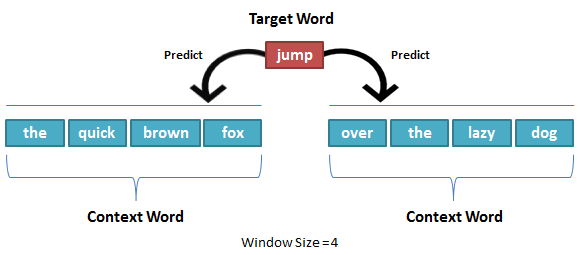

# “i like _____ language processing”

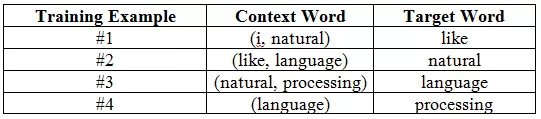

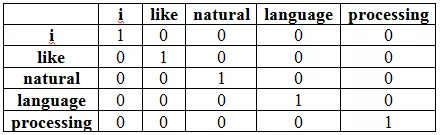

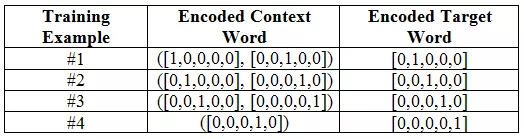

In [ ]:
kozmos_1000 = kozmos.sample(1000)
kozmos_1000.Star.value_counts()

In [ ]:
kozmos_1000.head()

In [ ]:
modelow2v = Word2Vec(kozmos_1000.vectors.to_list(), vector_size= 100, window=5, min_count=2)

In [ ]:
modelow2v.wv.key_to_index

In [ ]:
modelow2v.wv["show"]

In [ ]:
modelow2v.wv.most_similar("show")

## OOV out of vocabulary

In [ ]:
modelow2v.wv.most_similar("color")

In [ ]:
# Convertir cada review a vector (promedio de embeddings)
def vectorize_doc(doc, model):
    valid_words = [w for w in doc if w in model.wv]
    if not valid_words:
        return np.zeros(model.vector_size)
    return np.mean(model.wv[valid_words], axis=0)

In [ ]:
X = np.array([vectorize_doc(documento, modelow2v) for documento in kozmos_1000.vectors])

In [ ]:
y = np.array(kozmos_1000.Star.to_list())

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Entrenar clasificador
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rL = LogisticRegression(max_iter=200)
rL.fit(X_train, y_train)
# Evaluar el modelo
y_pred =rL.predict(X_test)
print( classification_report(y_test, y_pred))

In [ ]:
etiquetas = []
tokens = []
# agregar el vocabulario y configurar t-SNE
vocab =modelow2v.wv.key_to_index

for palabra in vocab.items():
    tokens.append(modelow2v.wv[palabra[0]])
    etiquetas.append(palabra[0])

tsne_modelo = TSNE( n_components= 2, perplexity=30, n_iter=300, verbose=1)

datos_entrenamiento = np.array(tokens)
nuevos_valores = tsne_modelo.fit_transform(datos_entrenamiento)


In [ ]:
df = pd.DataFrame(nuevos_valores, columns=["x", "y"])
df["Word"] = etiquetas

In [ ]:
import plotly.express as px
fig = px.scatter(df, x='x', y='y', text='Word',
                 title='t-SNE Visualization of Word Embeddings',
                 labels={'text': 'Word'},
                 hover_data=['Word'])
fig.update()

## Tarea 04: Clasificación de sentimientos con PySentimiento y modelo `nlptown/bert-base-multilingual-uncased-sentiment` de Hugging Face

### Objetivo
Implementar un flujo de **análisis de sentimientos multilingüe** utilizando dos enfoques complementarios:

1. **PySentimiento** como modelo ligero optimizado para texto en español.  
2. **Modelo de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`)**, un modelo BERT multilingüe capaz de analizar sentimientos en distintos idiomas.

El propósito es comparar ambos enfoques en términos de funcionamiento, salida de etiquetas y facilidad de aplicación sobre un conjunto de textos cortos.

---

### Descripción general
Esta tarea aborda la **clasificación automática de sentimientos** (positivo, negativo o neutral) en textos.  
Se emplearán dos estrategias distintas:
- Un **analizador preentrenado de PySentimiento**, basado en modelos BERT ligeros adaptados al español.  
- Un **modelo multilingüe BERT** disponible en la plataforma Hugging Face, entrenado sobre reseñas en múltiples idiomas, que predice una puntuación de 1 a 5 estrellas (de muy negativo a muy positivo).

El objetivo es aplicar ambos métodos sobre un mismo conjunto de frases en español e inglés, comparar los resultados y visualizar la distribución de las predicciones.

---

### Flujo de trabajo

1. **Instalación y carga de librerías**
   - Instalar `pysentimiento`, `transformers`, `torch` y `pandas`.  
   - Importar `create_analyzer` desde PySentimiento y las clases `pipeline`, `AutoTokenizer`, y `AutoModelForSequenceClassification` desde Hugging Face.

2. **Clasificación de sentimientos con PySentimiento**
   - Crear un analizador de sentimientos en español:  
     ```python
     from pysentimiento import create_analyzer
     analyzer = create_analyzer(task="sentiment", lang="es")
     ```
   - Procesar una lista de frases con `analyzer.predict()`.  
   - Guardar los resultados (etiqueta y probabilidades) en un DataFrame para análisis posterior.

3. **Clasificación con modelo de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`)**
   - Crear un pipeline con el modelo:
     ```python
     from transformers import pipeline
     sentiment_model = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")
     ```
   - Aplicar el modelo a las mismas frases usadas en PySentimiento.  
   - Interpretar las etiquetas devueltas (valores entre 1 y 5):
     - **1 estrella:** sentimiento muy negativo  
     - **2 estrellas:** sentimiento negativo  
     - **3 estrellas:** sentimiento neutral  
     - **4 estrellas:** sentimiento positivo  
     - **5 estrellas:** sentimiento muy positivo


# Analisis de sentimientos con modelos pre entrenados.

#Pysentimiento

Una biblioteca basada en Transformer para tareas de SocialNLP.

Actualmente admite:

* Análisis de Sentimiento (Español, Inglés)

* Análisis de emociones (español, inglés)

* Detección de discursos de odio (español, inglés)

In [ ]:
#Crear el objeto de pysentimiento
#Ejecutar una predicción del documento
#Analizar las información para todo el corpus

In [ ]:
from pysentimiento import create_analyzer

In [ ]:
sentimientos = create_analyzer(task="sentiment", lang="en")

In [ ]:
sentimientos.predict("Chatgpt is not that bad")

In [ ]:
def clasifica_pysentimiento(texto):
    if isinstance(texto, str) and len(texto) > 0:
        return sentimientos.predict(texto).output
    return -1

In [ ]:
kozmos_1000["pysentimiento"] = kozmos_1000.Review.apply(clasifica_pysentimiento)

In [ ]:
kozmos_1000.head()

# huggingface:
Hugging Face, una empresa que creó por primera vez una aplicación de chat para adolescentes aburridos, ofrece tecnologías de PNL de código abierto y, el año pasado, recaudó 15 millones de dólares para crear una biblioteca de PNL definitiva. Desde su aplicación de chat hasta el día de hoy, Hugging Face ha podido desarrollar rápidamente su experiencia en el procesamiento del lenguaje.

[huggingface](https://huggingface.co/)

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification #dependencias para ejecutar modelos de hugginface
import torch #dependencias de matrices, torch o tensors

In [ ]:
modelo = "nlptown/bert-base-multilingual-uncased-sentiment" #modelo a llamar

In [ ]:
tokeniza = AutoTokenizer.from_pretrained(modelo)

In [ ]:
token_docto = tokeniza.encode(kozmos_1000.Review.to_list()[0], return_tensors="pt") #tf

In [ ]:
print(token_docto)

In [ ]:
modelo_hf = AutoModelForSequenceClassification.from_pretrained(modelo)

In [ ]:
prediccion = modelo_hf(token_docto)

In [ ]:
prediccion.logits

In [ ]:
torch.argmax(prediccion.logits).item()+1

In [ ]:
def HFSentimientos(texto):
    if not isinstance(texto, str):
        texto = str(texto)
    if len(texto) < 512:
        tokens = tokeniza.encode(texto, return_tensors="pt")
        prediccion_SC = modelo_hf(tokens)
        return torch.argmax(prediccion_SC.logits).item()+1
    return -1

In [ ]:
kozmos_1000["hf"] = kozmos_1000.Review.apply(HFSentimientos)

In [ ]:
kozmos_1000.head()

##¿Cómo utilizarías el clasificador en todo el corpus?

## Laboratorio: Análisis de Sentimientos con VADER, PySentimiento y Hugging Face

**Objetivo**:
El objetivo de este laboratorio es aplicar tres métodos diferentes de análisis de sentimientos en las reseñas de productos de Amazon Kozmos:

1. VADER (usando NLTK).
2. PySentimiento.
3. Hugging Face con un modelo preentrenado.
4. Muestra gráficas de pastel para mostrar el procesamiento de los 3 modelos.

Al final del laboratorio, podrás comparar los resultados obtenidos por cada técnica y visualizarlos.